In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("-> Đã nạp thành công các thư viện EDA.")

-> Đã nạp thành công các thư viện EDA.


In [2]:
# Đọc file dữ liệu thô
data_path = '../data/raw/diabetes.csv'
if not os.path.exists(data_path):
    data_path = 'data/raw/diabetes.csv'

df = pd.read_csv(data_path)

print(f"Kích thước tập dữ liệu: {df.shape} dòng, {df.shape[1]} cột\n")
print("--- Thông tin kiểu dữ liệu ---")
print(df.info())

print("\n--- 5 dòng dữ liệu đầu tiên ---")
df.head()

Kích thước tập dữ liệu: (768, 9) dòng, 9 cột

--- Thông tin kiểu dữ liệu ---
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

--- 5 dòng dữ liệu đầu tiên ---


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Các chỉ số y tế không thể bằng 0
invalid_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Đếm số lượng số 0 ở từng cột
zero_counts = (df[invalid_zero_cols] == 0).sum()
zero_percent = (zero_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Số lượng giá trị 0': zero_counts,
    'Tỷ lệ (%)': zero_percent.round(2)
})

print("--- THỐNG KÊ GIÁ TRỊ 0 BẤT THƯỜNG ---")
print(missing_df)

--- THỐNG KÊ GIÁ TRỊ 0 BẤT THƯỜNG ---
               Số lượng giá trị 0  Tỷ lệ (%)
Glucose                         5       0.65
BloodPressure                  35       4.56
SkinThickness                 227      29.56
Insulin                       374      48.70
BMI                            11       1.43


C:\Users\Thanh Tien\AppData\Local\Temp\ipykernel_13728\3876674697.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Outcome', data=df, ax=axes[0], palette='Blues_d')
C:\Users\Thanh Tien\AppData\Local\Temp\ipykernel_13728\3876674697.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Không bệnh (0)', 'Có bệnh (1)'])


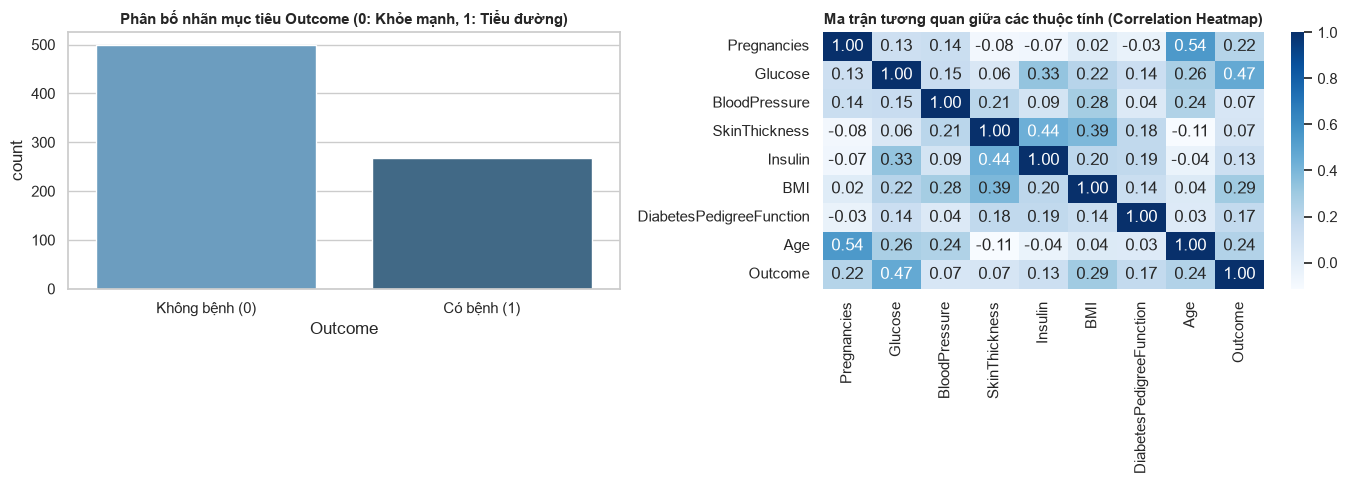

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Phân bố nhãn Outcome (Kiểm tra lệch lớp)
# Thêm [0] vào axes
sns.countplot(x='Outcome', data=df, ax=axes[0], palette='Blues_d')
axes[0].set_title('Phân bố nhãn mục tiêu Outcome (0: Khỏe mạnh, 1: Tiểu đường)', fontsize=11, fontweight='bold')
axes[0].set_xticklabels(['Không bệnh (0)', 'Có bệnh (1)'])

# Biểu đồ 2: Ma trận tương quan Correlation Heatmap
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='Blues', ax=axes[1], cbar=True)
axes[1].set_title('Ma trận tương quan giữa các thuộc tính (Correlation Heatmap)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
df_clean = df.copy()

# Thay 0 bằng NaN
for col in invalid_zero_cols:
    df_clean[col] = df_clean[col].replace(0, np.nan)
    # Điền NaN bằng Median tính theo từng nhóm Outcome
    df_clean[col] = df_clean[col].fillna(df_clean.groupby('Outcome')[col].transform('median'))

print("--- KIỂM TRA LẠI SAU KHI LÀM SẠCH ---")
print(f"Số lượng giá trị NaN còn lại: {df_clean.isnull().sum().sum()}")
df_clean.describe().round(2)

--- KIỂM TRA LẠI SAU KHI LÀM SẠCH ---
Số lượng giá trị NaN còn lại: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,121.68,72.39,29.09,141.75,32.43,0.47,33.24,0.35
std,3.37,30.46,12.11,8.89,89.10,6.88,0.33,11.76,0.48
min,0.00,44.00,24.00,7.00,14.00,18.20,0.08,21.00,0.00
25%,1.00,99.75,64.00,25.00,102.50,27.50,0.24,24.00,0.00
50%,3.00,117.00,72.00,28.00,102.50,32.05,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,169.50,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


In [7]:
os.makedirs('../data/processed', exist_ok=True)
output_path = '../data/processed/data_clean.csv'

df_clean.to_csv(output_path, index=False)
print(f"-> Đã xuất dữ liệu sạch thành công ra file: {output_path}")

-> Đã xuất dữ liệu sạch thành công ra file: ../data/processed/data_clean.csv
